# Unsupervised clustering of MECO facial action units: clip level

**Question.** Do the facial action units (AUs) of a person watching an emotion-inducing clip group
into clusters that correspond to what the person felt?

**Design decisions**

- **Unit of analysis = clip.** One clip is one stimulus block. Each clip has one self-reported emotion
  and one valence and arousal rating. Windows are used only to build clip features. A window-level
  analysis is included as a secondary check.
- **Target label = self-reported emotion** (what the patient felt). The intended stimulus is kept
  only as a reference.
- **Features = AUs only, 175 statistics per window**, averaged over each clip. No pose, no session,
  no subject information.
- **Clustering objective = one cluster per felt emotion category (k = 6).** This is fixed in advance
  from the objective and not chosen by looking at labels. A data-driven k is reported as a secondary result.
- **No labels are used to build features or to fit clusters.** Labels are used only to evaluate
  the clusters and to colour the figures.

**Steps:** load, check clip segmentation, normalise, features, clip features, clustering,
evaluation against a label-permutation null, subject-confound check, figures, save.

In [5]:
# ============================================================
# 0. Configuration (change values here only)
# ============================================================
import os, re, glob, pickle, time, json, warnings, platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_completeness_v_measure, silhouette_score)
import joblib

SEED = 42
SOURCE = "data/MECO/Video"     # folder (or one file) with video_S*.pkl
OUT_DIR = "meco_clip_clustering_outputs"

LABEL = "self"              # felt emotion = self-report. "stim" = intended stimulus (reference only)
K_OBJECTIVE = 6             # one cluster per self-reported emotion category (fixed in advance)
K_RANGE = range(2, 11)      # data-driven k, reported as a secondary result
N_RESTARTS = 10             # k-means restarts for stability
STABILITY_MIN = 0.6         # minimum mean ARI between restarts for a data-driven k to be eligible

# clip quality control
MIN_WINDOWS_PER_CLIP = 20   # 20 windows = 80 s; the protocol clips are 2-4 min
MIN_PURITY = 0.5            # share of a clip's windows carrying its most common self-report
REQUIRE_SIX_CLIPS = True    # drop sessions that do not have exactly 6 stimulus blocks with 6 distinct emotions

# window handling and features
MAX_MISSING_FRAC = 0.5      # drop windows where more than this share of frames failed detection
N_PCA = 50                  # PCA components (capped at the number of units)
PERPLEXITIES = [10, 30, 50] # t-SNE perplexities; the first is the main display
HDBSCAN_MIN_CLUSTER = 20    # secondary density-based clustering

N_NULL = 2000               # label permutations for the null distribution
RUN_WINDOW_LEVEL = True     # secondary: cluster the individual windows
SIL_SAMPLE_WINDOWS = 5000   # window-level silhouette is subsampled (memory)

assert LABEL in ("self", "stim")
np.random.seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
print({"sklearn": sklearn.__version__, "numpy": np.__version__, "python": platform.python_version(),
       "label": LABEL, "K_objective": K_OBJECTIVE})

{'sklearn': '1.4.2', 'numpy': '1.26.4', 'python': '3.12.10', 'label': 'self', 'K_objective': 6}


## 1. Load AU windows with emotion names

The integer in `label_vi_class` (stimulus) means a different emotion in each session, so each session is
converted through its own `emotion_to_idx_vi`. The self-report `label_sa_class` uses the global
`emotion_to_idx_sa`. The session number is read **only** for the quality-control check in section 2; it is not
used in any feature, cluster or evaluation.

In [6]:
# ============================================================
# 1. Load AU windows
# ============================================================
CANON = {'happy': 'happiness', 'happiness': 'happiness', 'sad': 'sadness', 'sadness': 'sadness',
         'angry': 'angry', 'boredom': 'boredom', 'neutral': 'neutral', 'tension': 'tension'}
ORDER = ['angry', 'boredom', 'happiness', 'neutral', 'sadness', 'tension']
ID = {n: i for i, n in enumerate(ORDER)}
N_AU, N_FRAMES = 35, 16          # 17 intensity (AU_r) + 18 presence (AU_c) columns; 16 frames per window


def find_files(source=SOURCE):
    if os.path.isfile(source):
        return [source]
    return sorted(glob.glob(os.path.join(source, "**", "video_S*.pkl"), recursive=True))


def load_pickle(path):
    with open(path, "rb") as fh:
        return pickle.load(fh)


def load_windows(source=SOURCE):
    files = find_files(source)
    if not files:
        raise FileNotFoundError(f"No video_S*.pkl files under {source}")
    AU = []
    cols = {k: [] for k in ["subject", "session", "window", "trial_raw", "y_self", "y_stim",
                            "valence", "arousal", "miss_frac"]}
    for path in files:
        raw = load_pickle(path)
        subj = os.path.splitext(os.path.basename(path))[0]
        sa_name = {v: CANON[k] for k, v in raw["emotion_to_idx_sa"].items()}
        for sess in sorted(k for k in raw if re.fullmatch(r"session\d+", str(k))):
            s = raw[sess]
            vi_name = {v: CANON[k] for k, v in s["emotion_to_idx_vi"].items()}   # per session
            vi = np.asarray(s["label_vi_class"]).astype(int).ravel()
            sa = np.asarray(s["label_sa_class"]).astype(int).ravel()
            au = np.asarray(s["au_openface"], dtype=np.float32)
            n = len(vi)
            assert au.shape == (n, N_FRAMES, N_AU), f"{subj}/{sess}: AU shape {au.shape}, labels {n}"
            assert len(sa) == n and len(s["label_valence"]) == n and len(s["label_arousal"]) == n
            miss = np.all(au == 0, axis=-1)                 # failed detection = all-zero frame
            au[miss] = np.nan
            AU.append(au)
            cols["subject"] += [subj] * n
            cols["session"] += [int(re.search(r"\d+", sess).group())] * n
            cols["window"] += list(range(n))
            # stimulus block id inside this session (consecutive equal stimulus = one clip)
            block = np.concatenate([[0], np.cumsum(vi[1:] != vi[:-1])])
            cols["trial_raw"] += [f"{subj}|{sess}|{b}" for b in block]
            cols["y_stim"] += [ID[vi_name[v]] for v in vi]
            cols["y_self"] += [ID[sa_name[v]] for v in sa]
            cols["valence"] += list(np.asarray(s["label_valence"], dtype=float).ravel())
            cols["arousal"] += list(np.asarray(s["label_arousal"], dtype=float).ravel())
            cols["miss_frac"] += list(miss.mean(1))
    data = {k: np.asarray(v) for k, v in cols.items()}
    data["au"] = np.concatenate(AU)
    _, data["trial"] = np.unique(data["trial_raw"], return_inverse=True)   # global clip id
    return data


data = load_windows()
print(f"windows {len(data['y_self'])} | subjects {len(np.unique(data['subject']))} | "
      f"raw stimulus blocks {len(np.unique(data['trial']))}")

windows 30592 | subjects 42 | raw stimulus blocks 733


## 2. Clip segmentation and quality control

A clip is a run of consecutive windows with the same stimulus label. The protocol gives exactly six
clips per session with six different emotions. This section checks that, and records every clip that
fails a rule. Session appears here **only** as a check on the segmentation; it is not a feature.

In [7]:
# ============================================================
# 2. Clip table and quality control
# ============================================================
cdf = pd.DataFrame({"trial": data["trial"], "subject": data["subject"], "session": data["session"],
                    "y_self": data["y_self"], "y_stim": data["y_stim"],
                    "valence": data["valence"], "arousal": data["arousal"]})
clip = cdf.groupby("trial").agg(
    subject=("subject", "first"), session=("session", "first"),
    y_stim=("y_stim", "first"), n_windows=("y_stim", "size"),
    y_self=("y_self", lambda x: pd.Series(x).mode().iloc[0]),
    purity=("y_self", lambda x: pd.Series(x).value_counts(normalize=True).iloc[0]),
    valence=("valence", "mean"), arousal=("arousal", "mean"))

# sessions with exactly 6 clips and 6 distinct stimulus emotions
sess_check = clip.groupby(["subject", "session"]).agg(
    n_clips=("y_stim", "size"), n_distinct=("y_stim", "nunique"))
sess_ok = sess_check[(sess_check.n_clips == 6) & (sess_check.n_distinct == 6)]
print(f"sessions: {len(sess_check)} | with 6 clips and 6 distinct emotions: {len(sess_ok)}")
print("clips per session distribution:", sess_check.n_clips.value_counts().sort_index().to_dict())
print(f"raw clips total: {len(clip)} (protocol: {6 * len(sess_check)})")

bad_sess = sess_check.drop(sess_ok.index)
if len(bad_sess):
    print("\nSessions that do not match the protocol:")
    print(bad_sess.to_string())

clip["ok_session"] = [(s, se) in set(sess_ok.index) for s, se in zip(clip.subject, clip.session)]
clip["ok_length"] = clip.n_windows >= MIN_WINDOWS_PER_CLIP
clip["ok_purity"] = clip.purity >= MIN_PURITY
print("\nclips failing length rule:", int((~clip.ok_length).sum()),
      "| failing purity rule:", int((~clip.ok_purity).sum()))
print("clip length (windows): min", clip.n_windows.min(), "| median", clip.n_windows.median(),
      "| max", clip.n_windows.max())

keep_clip = clip.ok_length & clip.ok_purity
if REQUIRE_SIX_CLIPS:
    keep_clip &= clip.ok_session
clip["included"] = keep_clip
print(f"\nclips included: {int(keep_clip.sum())} of {len(clip)}")
clip.to_csv(os.path.join(OUT_DIR, "clip_qc_table.csv"))

sessions: 126 | with 6 clips and 6 distinct emotions: 118
clips per session distribution: {2: 2, 3: 4, 4: 1, 5: 1, 6: 118}
raw clips total: 733 (protocol: 756)

Sessions that do not match the protocol:
                   n_clips  n_distinct
subject   session                     
video_S13 3              4           4
video_S14 3              3           3
video_S17 3              3           3
video_S20 3              3           3
video_S35 3              2           2
video_S36 2              5           5
video_S37 1              3           3
video_S38 1              2           2

clips failing length rule: 0 | failing purity rule: 0
clip length (windows): min 20 | median 39.0 | max 88

clips included: 708 of 733


## 3. Per-subject normalisation and window selection

Each person's AU intensities are z-scored with their own frames. Presence (binary) columns stay 0/1.
Windows with too many failed frames are excluded, and so are windows of clips that fail QC.

In [8]:
# ============================================================
# 3. Normalise per subject and select windows
# ============================================================
flat = data["au"].reshape(-1, N_AU)
is_bin = np.array([np.isin(np.unique(flat[:, c][~np.isnan(flat[:, c])]), [0, 1]).all()
                   for c in range(N_AU)])
assert is_bin.sum() == 18 and is_bin[17:].all(), f"unexpected binary AU columns: {np.where(is_bin)[0]}"


def normalize_au(au, subject, is_bin):
    """z-score AU intensity columns with each subject's own frames. Presence columns unchanged."""
    out = au.copy()
    for s in np.unique(subject):
        idx = subject == s
        flat_s = au[idx].reshape(-1, au.shape[-1])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            mu = np.nanmean(flat_s, 0)
            sd = np.nanstd(flat_s, 0)
        mu = np.where(np.isnan(mu), 0.0, mu)
        sd = np.where(np.isnan(sd) | (sd < 1e-6), 1.0, sd)
        mu[is_bin] = 0.0
        sd[is_bin] = 1.0
        out[idx] = (au[idx] - mu) / sd
    return out


au_n = normalize_au(data["au"], data["subject"], is_bin)
win_keep = (data["miss_frac"] <= MAX_MISSING_FRAC) & clip.loc[data["trial"], "included"].to_numpy()
au_k = au_n[win_keep]
w = {k: v[win_keep] for k, v in data.items() if k not in ("au", "trial_raw")}
print(f"windows kept: {win_keep.sum()} of {win_keep.size}")

windows kept: 26923 of 30592


## 4. Features (175 per window) and clip features

For each window: mean, standard deviation, minimum, maximum and mean absolute frame-to-frame change of
each AU. A clip's feature vector is the **mean of its windows' feature vectors**, which keeps one
point per clip with the same 175 dimensions.

In [9]:
# ============================================================
# 4. Window features (175) and clip features
# ============================================================
def window_stats(a):
    """(n, 16, 35) -> (n, 175). NaN-aware summary statistics per AU."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        feats = [np.nanmean(a, 1), np.nanstd(a, 1), np.nanmin(a, 1), np.nanmax(a, 1),
                 np.nanmean(np.abs(np.diff(a, axis=1)), 1)]
    return np.nan_to_num(np.concatenate(feats, 1)).astype(np.float32)


Xw = window_stats(au_k)                              # (n_windows, 175)
clip_ids, clip_inv = np.unique(w["trial"], return_inverse=True)
n_clip = len(clip_ids)

# clip features: mean over the clip's windows
Xc = np.zeros((n_clip, Xw.shape[1]), np.float32)
np.add.at(Xc, clip_inv, Xw)
counts = np.bincount(clip_inv, minlength=n_clip)[:, None]
Xc /= counts

# clip-level labels and metadata (one row per clip, in clip_ids order)
cl = clip.loc[clip_ids]
y_clip_self = cl["y_self"].to_numpy()
y_clip_stim = cl["y_stim"].to_numpy()
val_clip = cl["valence"].to_numpy()
aro_clip = cl["arousal"].to_numpy()
subj_clip = cl["subject"].to_numpy()
print(f"window features {Xw.shape} | clip features {Xc.shape} | clips {n_clip}")
if n_clip < 100:
    print("WARNING: fewer than 100 clips. Clip-level results will be unstable; do not interpret them.")
print("clips per self-report category:", dict(zip(ORDER, np.bincount(y_clip_self, minlength=6).tolist())))
print("clips per stimulus category:   ", dict(zip(ORDER, np.bincount(y_clip_stim, minlength=6).tolist())))

window features (26923, 175) | clip features (690, 175) | clips 690
clips per self-report category: {'angry': 96, 'boredom': 50, 'happiness': 147, 'neutral': 161, 'sadness': 113, 'tension': 123}
clips per stimulus category:    {'angry': 114, 'boredom': 114, 'happiness': 118, 'neutral': 115, 'sadness': 114, 'tension': 115}


## 5. Generic analysis function

The same function is used at clip level (main) and window level (secondary):

1. standardise and reduce with PCA (fitted on the units, no labels);
2. t-SNE for display at several perplexities;
3. **k-means with k = 6** as the primary clustering (pre-specified);
4. a **data-driven k** (silhouette among stable solutions) and **HDBSCAN** as robustness checks;
5. agreement with the felt labels, compared with a **label-permutation null** (clip labels shuffled
   globally, so no session information is used);
6. confound check: how much clusters follow subject identity.

In [10]:
# ============================================================
# 5. Generic analysis (used for clip level and window level)
# ============================================================
def kmeans_fit(Z_, k, seed):
    return KMeans(n_clusters=k, n_init=10, random_state=seed).fit(Z_)


def stability(Z_, k, n_restarts=N_RESTARTS):
    labs = [kmeans_fit(Z_, k, s).labels_ for s in range(n_restarts)]
    pairs = [(i, j) for i in range(n_restarts) for j in range(i + 1, n_restarts)]
    return float(np.mean([adjusted_rand_score(labs[i], labs[j]) for i, j in pairs]))


def select_k(Z_, k_range, sil_sample=None):
    rows = []
    for k in k_range:
        sil = silhouette_score(Z_, kmeans_fit(Z_, k, SEED).labels_,
                               sample_size=sil_sample, random_state=SEED)
        rows.append({"k": k, "silhouette": sil, "stability": stability(Z_, k)})
    df = pd.DataFrame(rows)
    eligible = df[df["stability"] >= STABILITY_MIN]
    pool = eligible if len(eligible) else df
    return df, int(pool.loc[pool["silhouette"].idxmax(), "k"])


def agreement(cl_, lab):
    h, c, v = homogeneity_completeness_v_measure(lab, cl_)
    purity = pd.crosstab(cl_, lab).max(axis=1).sum() / len(lab)
    return {"ARI": adjusted_rand_score(lab, cl_), "NMI": normalized_mutual_info_score(lab, cl_),
            "homogeneity": h, "completeness": c, "V": v, "purity": purity}


def clip_mode_per_row(labels, row_clip):
    """Each row gets its unit's (clip's) most common label; returns one value per clip."""
    k = row_clip.max() + 1
    modes = np.zeros(k, dtype=int)
    for i in range(k):
        m = row_clip == i
        modes[i] = np.bincount(labels[m], minlength=len(ORDER)).argmax()
    return modes


def permutation_null(cluster_labels, labels, row_clip, n_perm, seed=SEED):
    """ARI between the clusters and labels when clip labels are shuffled across all clips."""
    rng = np.random.default_rng(seed)
    modes = clip_mode_per_row(labels, row_clip)
    null = np.empty(n_perm)
    for b in range(n_perm):
        null[b] = adjusted_rand_score(rng.permutation(modes)[row_clip], cluster_labels)
    return null


def subject_dominance(cluster_labels, subjects):
    tab = pd.crosstab(cluster_labels, subjects, normalize="index")
    return tab.max(axis=1)


def analyse(F, labels, row_clip, subjects, name, sil_sample=None, perps=PERPLEXITIES):
    """F: (n, p) features; labels: (n,) felt label per row; row_clip: clip index per row."""
    out = {"name": name, "n": len(F)}
    sc = StandardScaler().fit(F)
    n_comp = min(N_PCA, len(F) - 1, F.shape[1])
    pca = PCA(n_components=n_comp, random_state=SEED).fit(sc.transform(F))
    Z = pca.transform(sc.transform(F))
    out["pca_var_explained"] = float(pca.explained_variance_ratio_.sum())

    # t-SNE for display
    emb = {}
    for p in perps:
        perp = min(p, (len(F) - 1) // 3)
        emb[p] = TSNE(n_components=2, perplexity=perp, init="pca", learning_rate="auto",
                      random_state=SEED).fit_transform(Z)
    out["emb"] = emb

    # primary: k = 6, fixed in advance
    km6 = kmeans_fit(Z, K_OBJECTIVE, SEED)
    out["clusters_k6"] = km6.labels_
    out["model_k6"] = km6

    # secondary: data-driven k
    sel, k_data = select_k(Z, K_RANGE, sil_sample=sil_sample)
    out["selection"] = sel
    out["k_data"] = k_data
    out["clusters_data"] = kmeans_fit(Z, k_data, SEED).labels_

    # robustness: HDBSCAN (noise = -1)
    mcs = min(max(HDBSCAN_MIN_CLUSTER, len(F) // 40), max(2, len(F) // 3))   # must not exceed the sample size
    hd = HDBSCAN(min_cluster_size=mcs, min_samples=min(mcs, len(F) - 1), copy=True).fit_predict(Z)
    out["clusters_hdbscan"] = hd
    out["hdbscan_noise_frac"] = float((hd == -1).mean())

    # agreement with the felt labels and null distribution
    null = permutation_null(out["clusters_k6"], labels, row_clip, N_NULL)
    out["agree_k6"] = agreement(out["clusters_k6"], labels)
    out["agree_k6"]["p_value"] = float((np.sum(null >= out["agree_k6"]["ARI"]) + 1) / (N_NULL + 1))
    out["null_ari"] = null
    out["agree_data"] = agreement(out["clusters_data"], labels)
    keep_hd = hd != -1
    if keep_hd.sum() > 0 and len(np.unique(hd[keep_hd])) > 1:
        out["agree_hdbscan"] = agreement(hd[keep_hd], labels[keep_hd])   # non-noise rows only
    else:
        out["agree_hdbscan"] = None                                      # no density clusters found

    # confound: subject identity
    out["ARI_subject_k6"] = adjusted_rand_score(subjects, out["clusters_k6"])
    out["dominant_subject_share_k6"] = subject_dominance(out["clusters_k6"], subjects).round(3).to_dict()
    out["Z"] = Z
    out["scaler"] = sc
    out["pca"] = pca
    return out


clip_res = analyse(Xc, y_clip_self if LABEL == "self" else y_clip_stim,
                   np.arange(n_clip), subj_clip, "clip level")
print("clip level | k = 6 agreement with", LABEL, "label:")
print({k: round(float(v), 3) for k, v in clip_res["agree_k6"].items()})
print("data-driven k =", clip_res["k_data"], "| agreement:", {k: round(float(v), 3) for k, v in clip_res["agree_data"].items()})
if clip_res["agree_hdbscan"] is None:
    print("HDBSCAN: no density clusters found (noise fraction", round(clip_res["hdbscan_noise_frac"], 3), ")")
else:
    print("HDBSCAN noise fraction:", round(clip_res["hdbscan_noise_frac"], 3),
          "| agreement on non-noise clips:", {k: round(float(v), 3) for k, v in clip_res["agree_hdbscan"].items()})
print("ARI(clusters, subject):", round(clip_res["ARI_subject_k6"], 3),
      "| dominant subject share per cluster:", clip_res["dominant_subject_share_k6"])

clip level | k = 6 agreement with self label:
{'ARI': 0.004, 'NMI': 0.016, 'homogeneity': 0.016, 'completeness': 0.016, 'V': 0.016, 'purity': 0.267, 'p_value': 0.061}
data-driven k = 2 | agreement: {'ARI': 0.0, 'NMI': 0.002, 'homogeneity': 0.002, 'completeness': 0.004, 'V': 0.002, 'purity': 0.235}
HDBSCAN: no density clusters found (noise fraction 1.0 )
ARI(clusters, subject): 0.045 | dominant subject share per cluster: {0: 0.144, 1: 0.064, 2: 0.144, 3: 0.143, 4: 0.079, 5: 0.127}


## 6. Clip-level selection of k (secondary)

Silhouette and stability for each candidate k. This is reported for transparency. The primary result
above uses k = 6, which is set by the objective.

In [11]:
print(clip_res["selection"].round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(clip_res["selection"]["k"], clip_res["selection"]["silhouette"], "o-", label="silhouette")
ax.plot(clip_res["selection"]["k"], clip_res["selection"]["stability"], "s-", label="stability")
ax.axhline(STABILITY_MIN, color="grey", ls="--", lw=1)
ax.axvline(K_OBJECTIVE, color="green", ls=":", lw=1.5, label="objective k = 6")
ax.axvline(clip_res["k_data"], color="red", ls=":", lw=1, label=f"data-driven k = {clip_res['k_data']}")
ax.set_xlabel("k"); ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.set_title("Clip level: choice of k")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "clip_k_selection.png"), dpi=150); plt.show()

 k  silhouette  stability
 2       0.155      0.978
 3       0.075      0.944
 4       0.068      0.829
 5       0.071      0.796
 6       0.068      0.785
 7       0.066      0.679
 8       0.063      0.610
 9       0.062      0.668
10       0.059      0.584


<Figure size 700x350 with 1 Axes>

## 7. Agreement between clusters and felt emotion

Counts and row-normalised shares of each cluster per felt category, and the null distribution of the
ARI from permuting clip labels.

Counts (clusters x felt category):
felt       angry  boredom  happiness  neutral  sadness  tension
cluster                                                        
cluster 0     18        5         22       34       18       14
cluster 1     14        7         42       23       18       21
cluster 2     15       12         23       27       20       21
cluster 3      5        1         11        9        2        7
cluster 4     32       11         27       48       35       38
cluster 5     12       14         22       20       20       22

Row-normalised:
felt       angry  boredom  happiness  neutral  sadness  tension
cluster                                                        
cluster 0   0.16     0.05       0.20     0.31     0.16     0.13
cluster 1   0.11     0.06       0.34     0.18     0.14     0.17
cluster 2   0.13     0.10       0.19     0.23     0.17     0.18
cluster 3   0.14     0.03       0.31     0.26     0.06     0.20
cluster 4   0.17     0.06       0.14     0.25     0.

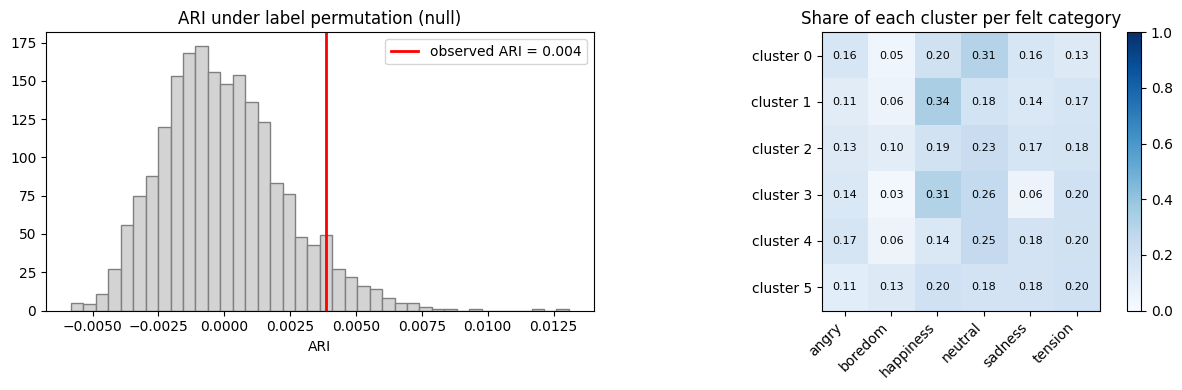

In [12]:
def contingency(cl_, lab):
    ct = pd.crosstab(pd.Series([f"cluster {c}" for c in cl_], name="cluster"),
                     pd.Series([ORDER[i] for i in lab], name="felt"))
    return ct


felt_clip = y_clip_self if LABEL == "self" else y_clip_stim
ct = contingency(clip_res["clusters_k6"], felt_clip)
print("Counts (clusters x felt category):")
print(ct.to_string())
norm = ct.div(ct.sum(axis=1), axis=0)
print("\nRow-normalised:")
print(norm.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(clip_res["null_ari"], bins=40, color="lightgrey", edgecolor="grey")
axes[0].axvline(clip_res["agree_k6"]["ARI"], color="red", lw=2,
                label=f"observed ARI = {clip_res['agree_k6']['ARI']:.3f}")
axes[0].set_title("ARI under label permutation (null)"); axes[0].set_xlabel("ARI"); axes[0].legend()
im = axes[1].imshow(norm.to_numpy(), cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(range(len(ORDER))); axes[1].set_xticklabels(ORDER, rotation=45, ha="right")
axes[1].set_yticks(range(norm.shape[0])); axes[1].set_yticklabels(norm.index)
for i in range(norm.shape[0]):
    for j in range(norm.shape[1]):
        axes[1].text(j, i, f"{norm.to_numpy()[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[1].set_title("Share of each cluster per felt category")
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "clip_agreement.png"), dpi=150); plt.show()

## 8. Clip-level figures

Each point is one clip. The panels show the k = 6 clusters, the felt category, the intended stimulus,
valence, arousal and subject (confound check), at each perplexity.

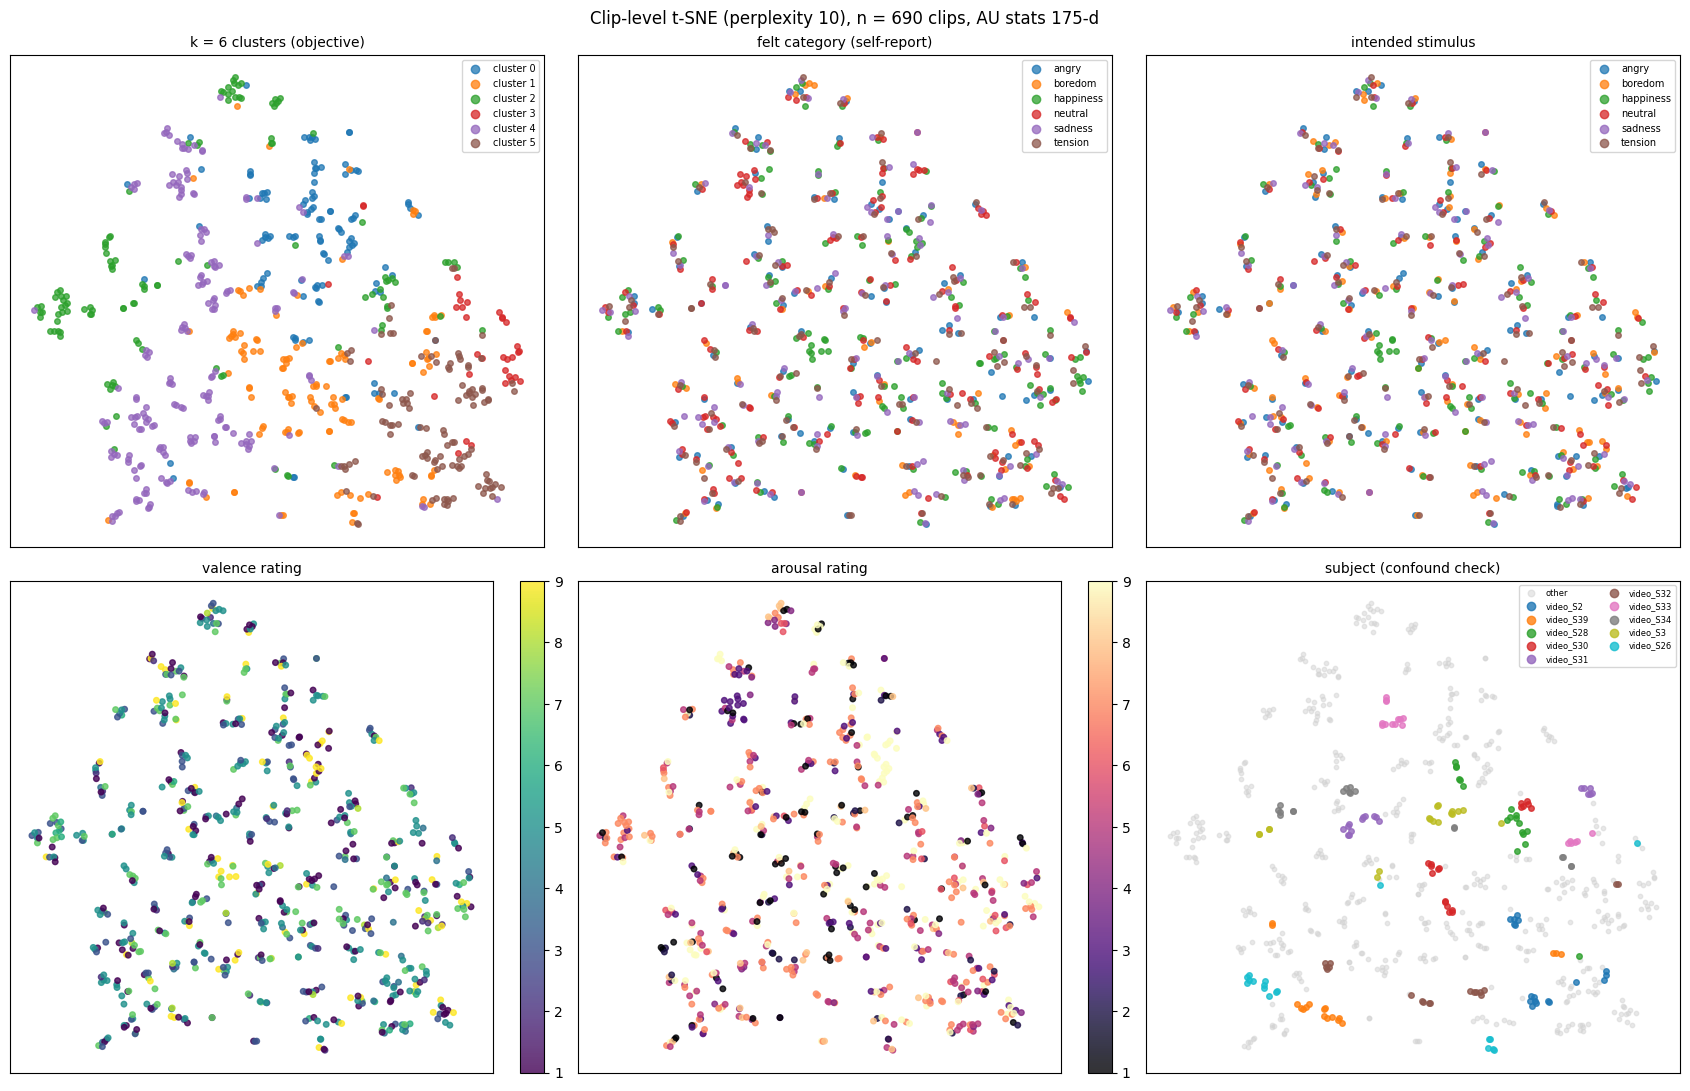

In [13]:
cmap10 = plt.get_cmap("tab10")


def scatter_cat(ax, xy, codes, names, title):
    for i, nm in enumerate(names):
        m = codes == i
        if m.any():
            ax.scatter(xy[m, 0], xy[m, 1], s=16, alpha=0.75, color=cmap10(i % 10), label=str(nm))
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(fontsize=7, markerscale=1.5, loc="best")


def clip_figure(res, perp):
    xy = res["emb"][perp]
    felt = y_clip_self if LABEL == "self" else y_clip_stim
    fig, axes = plt.subplots(2, 3, figsize=(17, 11))
    scatter_cat(axes[0, 0], xy, res["clusters_k6"], [f"cluster {c}" for c in range(K_OBJECTIVE)],
                f"k = {K_OBJECTIVE} clusters (objective)")
    scatter_cat(axes[0, 1], xy, felt, ORDER, f"felt category ({LABEL}-report)")
    scatter_cat(axes[0, 2], xy, y_clip_stim, ORDER, "intended stimulus")
    for ax, vals, name, cmap in [(axes[1, 0], val_clip, "valence rating", "viridis"),
                                 (axes[1, 1], aro_clip, "arousal rating", "magma")]:
        sc = ax.scatter(xy[:, 0], xy[:, 1], c=vals, cmap=cmap, s=16, alpha=0.8)
        ax.set_title(name, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(sc, ax=ax, fraction=0.046)
    top = pd.Series(subj_clip).value_counts().index[:10].tolist()
    ax = axes[1, 2]
    other = ~np.isin(subj_clip, top)
    ax.scatter(xy[other, 0], xy[other, 1], s=10, color="lightgrey", alpha=0.5, label="other")
    for i, s in enumerate(top):
        m = subj_clip == s
        ax.scatter(xy[m, 0], xy[m, 1], s=16, alpha=0.8, color=cmap10(i), label=s)
    ax.set_title("subject (confound check)", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(fontsize=6, markerscale=1.5, ncol=2)
    plt.suptitle(f"Clip-level t-SNE (perplexity {perp}), n = {len(xy)} clips, AU stats 175-d", fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"clip_tsne_panels_perp{perp}.png"), dpi=130)
    plt.show()


clip_figure(clip_res, PERPLEXITIES[0])

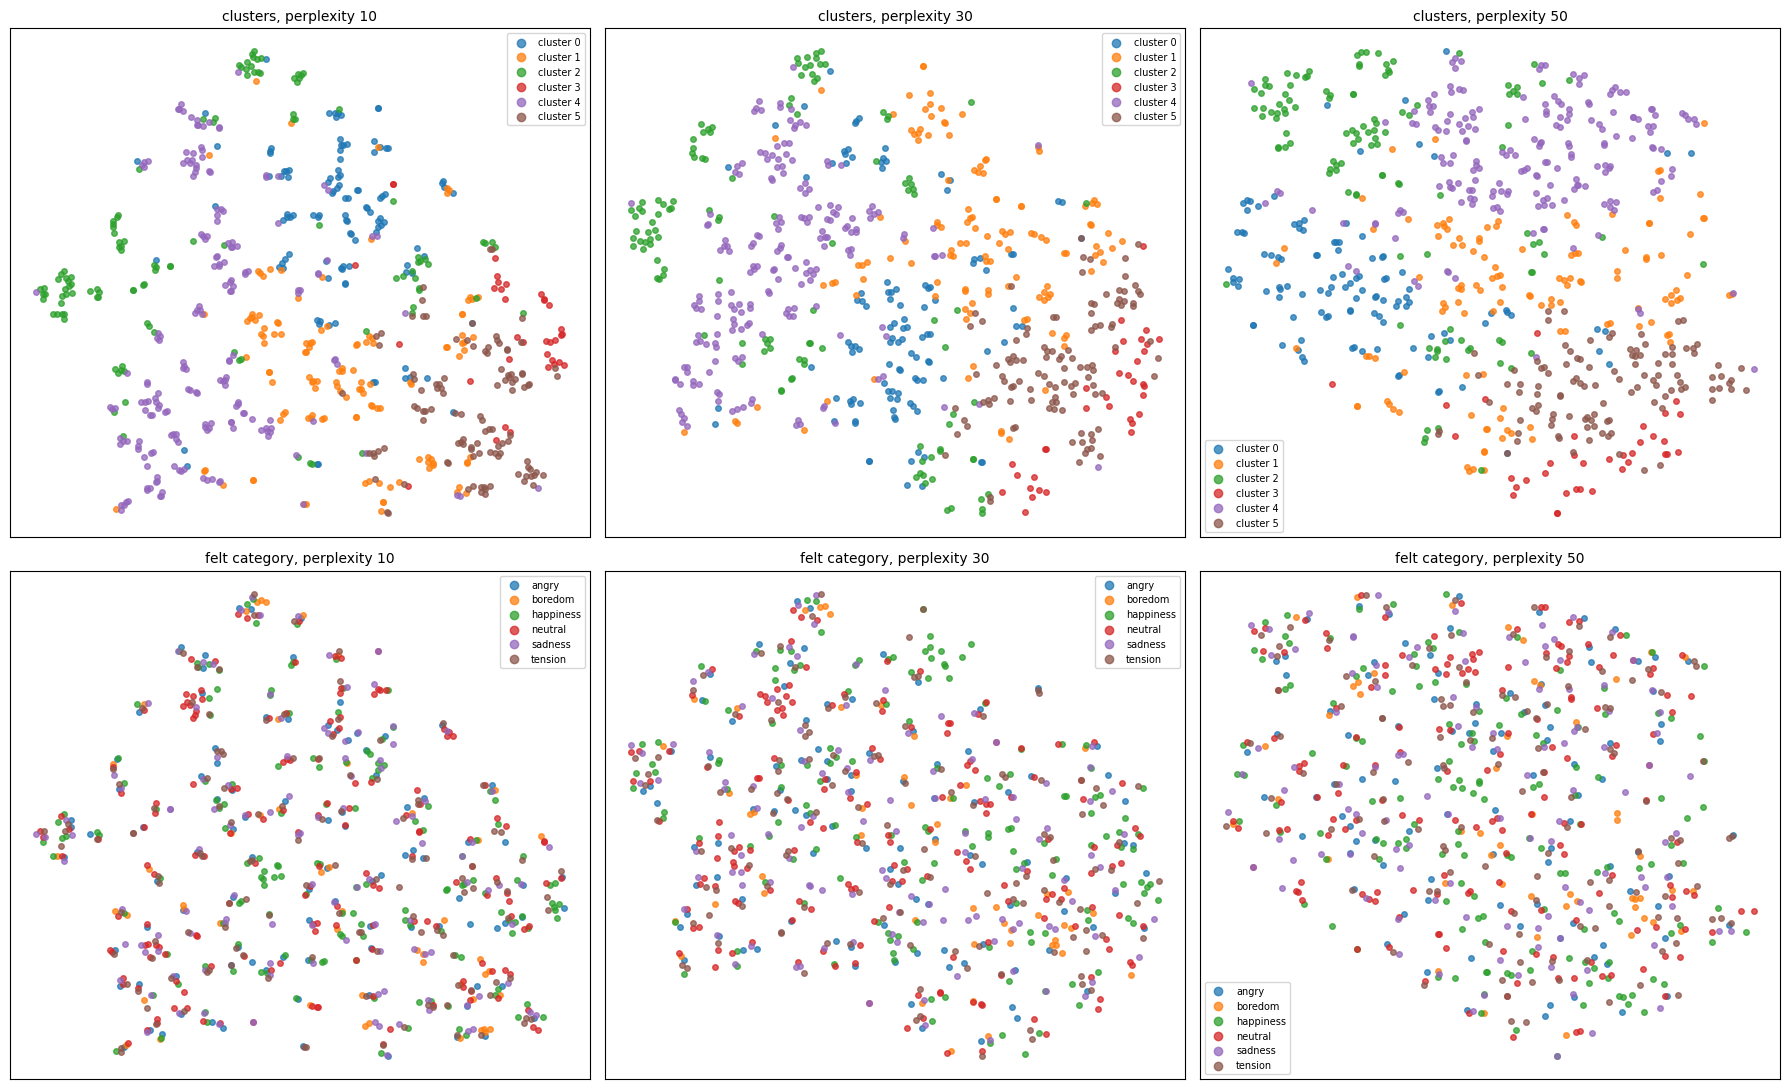

In [14]:
# robustness across perplexities: clusters and felt labels side by side
fig, axes = plt.subplots(2, len(PERPLEXITIES), figsize=(6 * len(PERPLEXITIES), 11))
felt = y_clip_self if LABEL == "self" else y_clip_stim
for j, p in enumerate(PERPLEXITIES):
    xy = clip_res["emb"][p]
    scatter_cat(axes[0, j], xy, clip_res["clusters_k6"], [f"cluster {c}" for c in range(K_OBJECTIVE)],
                f"clusters, perplexity {p}")
    scatter_cat(axes[1, j], xy, felt, ORDER, f"felt category, perplexity {p}")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "clip_tsne_perplexities.png"), dpi=120); plt.show()

## 9. Window level (secondary check)

The same analysis applied to individual windows. Each window carries its clip's felt label. Windows
from the same clip are not independent, so the clip-level result above is the one to report.

In [15]:
if RUN_WINDOW_LEVEL:
    win_felt = w["y_self"] if LABEL == "self" else w["y_stim"]
    win_res = analyse(Xw, win_felt, clip_inv, w["subject"], "window level",
                      sil_sample=SIL_SAMPLE_WINDOWS)
    print("window level | k = 6 agreement:", {k: round(float(v), 3) for k, v in win_res["agree_k6"].items()})
    print("data-driven k =", win_res["k_data"], "| HDBSCAN noise:", round(win_res["hdbscan_noise_frac"], 3))
    print("ARI(clusters, subject):", round(win_res["ARI_subject_k6"], 3))
else:
    win_res = None

window level | k = 6 agreement: {'ARI': 0.01, 'NMI': 0.015, 'homogeneity': 0.015, 'completeness': 0.015, 'V': 0.015, 'purity': 0.275, 'p_value': 0.0}
data-driven k = 2 | HDBSCAN noise: 1.0
ARI(clusters, subject): 0.029


## 10. Save results

The saved chain (scaler, PCA, k-means) is fitted on clip features. To apply it to new data (for
example the Japanese recordings, if clips can be defined there), the new windows must be built the same
way: per-person normalisation, the 175 statistics, averaged per clip.

In [16]:
clip_out = pd.DataFrame({
    "clip_id": clip_ids, "subject": subj_clip,
    "felt_self_report": [ORDER[i] for i in y_clip_self],
    "stimulus": [ORDER[i] for i in y_clip_stim],
    "valence": val_clip, "arousal": aro_clip,
    "n_windows": counts.ravel(),
    "cluster_k6": clip_res["clusters_k6"],
    "cluster_data_driven": clip_res["clusters_data"],
    "cluster_hdbscan": clip_res["clusters_hdbscan"],
    "tsne1": clip_res["emb"][PERPLEXITIES[0]][:, 0],
    "tsne2": clip_res["emb"][PERPLEXITIES[0]][:, 1],
})
clip_out.to_csv(os.path.join(OUT_DIR, "clip_clusters.csv"), index=False)

joblib.dump({"scaler": clip_res["scaler"], "pca": clip_res["pca"], "kmeans_k6": clip_res["model_k6"],
             "features": "window stats (175), averaged per clip",
             "max_missing_frac": MAX_MISSING_FRAC, "is_binary_au": is_bin,
             "k": K_OBJECTIVE, "sklearn_version": sklearn.__version__},
            os.path.join(OUT_DIR, "clip_cluster_model.joblib"))

summary = {
    "label": LABEL, "k_objective": K_OBJECTIVE, "k_data": clip_res["k_data"],
    "clips_total": int(len(clip)), "clips_included": int(n_clip),
    "clip_k6": {k: float(v) for k, v in clip_res["agree_k6"].items()},
    "clip_data_driven": {k: float(v) for k, v in clip_res["agree_data"].items()},
    "clip_hdbscan_noise_frac": clip_res["hdbscan_noise_frac"],
    "clip_hdbscan": ({k: float(v) for k, v in clip_res["agree_hdbscan"].items()}
                     if clip_res["agree_hdbscan"] is not None else None),
    "clip_ARI_subject": float(clip_res["ARI_subject_k6"]),
    "window_k6": {k: float(v) for k, v in win_res["agree_k6"].items()} if win_res else None,
}
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2)
print("saved:", sorted(os.listdir(OUT_DIR)))

saved: ['clip_agreement.png', 'clip_cluster_model.joblib', 'clip_clusters.csv', 'clip_k_selection.png', 'clip_qc_table.csv', 'clip_tsne_panels_perp10.png', 'clip_tsne_perplexities.png', 'summary.json']
